# Cookie Cats A/B Test: Should the First Gate Move from Level 30 to Level 40?

**Context.** Cookie Cats is a mobile puzzle game by Tactile Entertainment. Players periodically hit a *gate* that forces them to wait or make an in-app purchase before continuing. In this experiment, 90,189 new installs were randomly assigned to see the first gate at level 30 (`gate_30`, control) or at level 40 (`gate_40`, treatment).

**Decision to support.** Should the gate be moved to level 40?

**Metrics**

| Role | Metric | Why |
|---|---|---|
| Primary | 7-day retention | Closest available proxy for long-term engagement and lifetime value |
| Secondary | 1-day retention | Early signal; most players have not reached either gate after one day |
| Guardrail | Game rounds played in the first 14 days | Checks that a retention change is not paid for with lower engagement |

**Analysis plan.** (1) data quality and randomisation checks, (2) frequentist test on retention, (3) Bayesian view of the same question, (4) guardrail metric, (5) sensitivity of the test, (6) recommendation.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from stats_utils import (
    srm_test, two_proportion_ztest, bootstrap_mean_diff,
    bayesian_ab, mde_two_proportions, required_n_per_group,
)

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8, "axes.axisbelow": True,
})

df = pd.read_csv("../data/cookie_cats.csv")
df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## 1. Data quality checks

In [2]:
print(f"Rows: {len(df):,}")
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicate user ids: {df['userid'].duplicated().sum()}")
print(f"Players with 0 game rounds: {(df['sum_gamerounds'] == 0).sum():,} ({(df['sum_gamerounds'] == 0).mean():.1%})")
df["sum_gamerounds"].describe(percentiles=[0.5, 0.9, 0.99]).round(1)

Rows: 90,189
Missing values: 0
Duplicate user ids: 0
Players with 0 game rounds: 3,994 (4.4%)


count    90189.0
mean        51.9
std        195.1
min          0.0
50%         16.0
90%        134.0
99%        493.0
max      49854.0
Name: sum_gamerounds, dtype: float64

In [3]:
df.nlargest(3, "sum_gamerounds")

,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True
7912,871500,gate_30,2961,True,True
29417,3271615,gate_40,2640,True,False


**Findings**

- No missing values and no duplicate users, so each row is one independent player.
- 3,994 players (4.4%) installed the game but never played a round. I keep them: assignment happened at install, so dropping them would turn an intention-to-treat comparison into a comparison of self-selected players.
- One player logged 49,854 rounds in 14 days, roughly 17 times the next highest value (2,961). That is about one round every 24 seconds around the clock, so it is almost certainly a bot or a logging error. Retention is a yes/no metric and is unaffected, but this single row would distort any comparison of means, so I exclude it **for the game-rounds analysis only**.

### Sample Ratio Mismatch (SRM)

In [4]:
a = df[df["version"] == "gate_30"]   # control
b = df[df["version"] == "gate_40"]   # treatment

srm = srm_test(len(a), len(b))
print(f"gate_30: {srm['n_a']:,}   gate_40: {srm['n_b']:,}   share of control: {srm['share_a']:.2%}")
print(f"chi-square = {srm['chi2']:.2f}, p = {srm['p_value']:.4f}")

gate_30: 44,700   gate_40: 45,489   share of control: 49.56%
chi-square = 6.90, p = 0.0086


**Interpretation.** With a 50/50 split we would expect about 45,095 players per arm; we observe 44,700 vs 45,489 (49.56% in control). The chi-square p-value is 0.0086.

This is a grey zone. It is above the strict p < 0.001 threshold that experimentation platforms commonly use to block a readout, so I proceed. But it is below 0.05, and an imbalance of 789 users is larger than I would expect from chance alone. In a live setting I would ask engineering to check the assignment and logging pipeline (for example, whether one variant loses more installs before the first event is logged) before making a final call. I carry this forward as a stated limitation rather than ignoring it.

## 2. Retention: frequentist analysis

In [5]:
rows, res = [], {}
for metric in ["retention_1", "retention_7"]:
    r = two_proportion_ztest(a[metric].sum(), len(a), b[metric].sum(), len(b))
    res[metric] = r
    rows.append({
        "metric": metric,
        "gate_30": f"{r['p_a']:.2%}", "gate_40": f"{r['p_b']:.2%}",
        "abs diff (pp)": round(r["abs_diff"] * 100, 2),
        "95% CI (pp)": f"[{r['ci_low']*100:.2f}, {r['ci_high']*100:.2f}]",
        "relative": f"{r['rel_diff']:.1%}",
        "p-value": round(r["p_value"], 4),
    })
pd.DataFrame(rows).set_index("metric")

,gate_30,gate_40,abs diff (pp),95% CI (pp),relative,p-value
metric,,,,,,
retention_1,44.82%,44.23%,-0.59,"[-1.24, 0.06]",-1.3%,0.0744
retention_7,19.02%,18.20%,-0.82,"[-1.33, -0.31]",-4.3%,0.0016


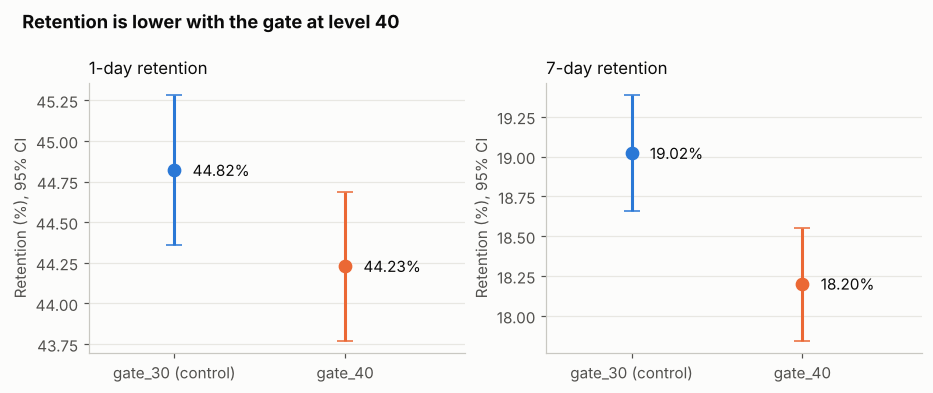

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.6))
for ax, metric, title in zip(axes, ["retention_1", "retention_7"], ["1-day retention", "7-day retention"]):
    for i, (grp, col) in enumerate([(a, BLUE), (b, ORANGE)]):
        p, n = grp[metric].mean(), len(grp)
        half = 1.96 * np.sqrt(p * (1 - p) / n)
        ax.errorbar(i, p * 100, yerr=half * 100, fmt="o", color=col, ms=8, lw=2, capsize=5)
        ax.annotate(f"{p:.2%}", (i, p * 100), xytext=(12, 0), textcoords="offset points", va="center", color=INK)
    ax.set_xticks([0, 1], ["gate_30 (control)", "gate_40"])
    ax.set_xlim(-0.5, 1.7)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_ylabel("Retention (%), 95% CI")
    ax.grid(axis="x", visible=False)
fig.suptitle("Retention is lower with the gate at level 40", x=0.02, ha="left", fontsize=12, weight="bold")
fig.tight_layout()
fig.savefig("../figures/retention_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

**Interpretation**

- **7-day retention (primary):** 19.02% for `gate_30` vs 18.20% for `gate_40`, a drop of 0.82 percentage points (95% CI −1.33 to −0.31, p = 0.0016). The whole interval sits below zero, so the data are not consistent with "no effect" or with `gate_40` being better. In relative terms that is 4.3% fewer players still active after a week.
- **1-day retention (secondary):** 44.82% vs 44.23%, a drop of 0.59 pp (95% CI −1.24 to +0.06, p = 0.074). Same direction, but the interval includes zero, so on its own this is not conclusive. That is plausible: after one day few players have reached level 30, so the two versions have barely started to differ.
- **Multiple comparisons:** I test two retention metrics. Under a Bonferroni correction (α = 0.05 / 2 = 0.025) the 7-day result remains significant, and 7-day retention was designated as primary before looking at results.
- **Why a z-test:** retention is binary and each arm has about 45,000 players, so the normal approximation for a difference in proportions is very accurate here.

## 3. Retention: Bayesian analysis

In [7]:
bayes = {}
for metric in ["retention_1", "retention_7"]:
    bayes[metric] = bayesian_ab(a[metric].sum(), len(a), b[metric].sum(), len(b))
    r = bayes[metric]
    print(f"{metric}: P(gate_40 better) = {r['prob_b_better']:.2%} | "
          f"95% credible interval for diff = [{r['cri_low']*100:.2f}, {r['cri_high']*100:.2f}] pp | "
          f"expected loss if we ship gate_40 = {r['expected_loss_b']*100:.3f} pp, if we keep gate_30 = {r['expected_loss_a']*100:.4f} pp")

retention_1: P(gate_40 better) = 3.77% | 95% credible interval for diff = [-1.24, 0.06] pp | expected loss if we ship gate_40 = 0.595 pp, if we keep gate_30 = 0.0050 pp
retention_7: P(gate_40 better) = 0.08% | 95% credible interval for diff = [-1.33, -0.31] pp | expected loss if we ship gate_40 = 0.819 pp, if we keep gate_30 = 0.0001 pp


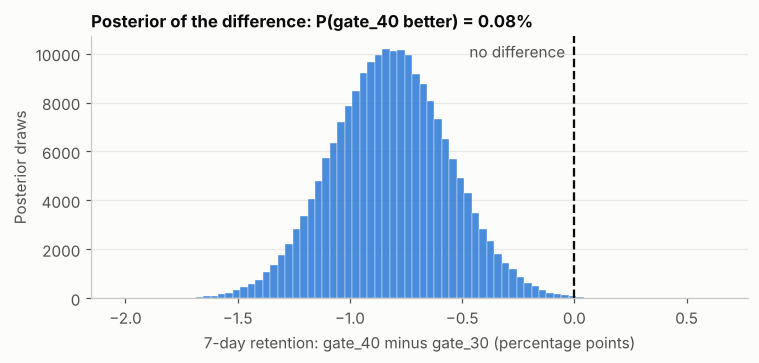

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.4))
s = bayes["retention_7"]["samples"] * 100
ax.hist(s, bins=80, color=BLUE, alpha=0.85, edgecolor="#fcfcfb", linewidth=0.3)
ax.axvline(0, color=INK, lw=1.5, ls="--")
ax.annotate("no difference", (0, ax.get_ylim()[1] * 0.92), xytext=(-6, 0), textcoords="offset points", ha="right", color=MUTED)
ax.set_xlabel("7-day retention: gate_40 minus gate_30 (percentage points)")
ax.set_ylabel("Posterior draws")
ax.set_title(f"Posterior of the difference: P(gate_40 better) = {bayes['retention_7']['prob_b_better']:.2%}", loc="left", fontsize=11, weight="bold")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig("../figures/posterior_retention_7.png", dpi=160, bbox_inches="tight")
plt.show()

**Interpretation.** With a uniform Beta(1, 1) prior on each retention rate, the probability that `gate_40` has higher 7-day retention than `gate_30` is about 0.1%; for 1-day retention it is about 4%.

The Bayesian and frequentist analyses agree, which is expected with this much data and a flat prior. I include both because they answer different questions. The p-value says how surprising the data would be if there were no effect. The posterior probability answers the question a product manager actually asks: "how likely is it that the new version is better?" Expected loss adds a decision view: keeping `gate_30` risks essentially nothing, while shipping `gate_40` is expected to cost about 0.8 pp of 7-day retention.

## 4. Guardrail: game rounds played

In [9]:
clean = df[df["sum_gamerounds"] < 10_000]          # drops the single 49,854-round outlier
ga = clean.loc[clean["version"] == "gate_30", "sum_gamerounds"]
gb = clean.loc[clean["version"] == "gate_40", "sum_gamerounds"]

boot = bootstrap_mean_diff(ga, gb, n_boot=5000)
mwu = stats.mannwhitneyu(ga, gb, alternative="two-sided")

print(f"Mean rounds   gate_30: {ga.mean():.2f}   gate_40: {gb.mean():.2f}")
print(f"Median rounds gate_30: {ga.median():.0f}      gate_40: {gb.median():.0f}")
print(f"Skewness: {stats.skew(clean['sum_gamerounds']):.1f}")
print(f"Bootstrap mean difference: {boot['mean_diff']:.2f} rounds, 95% CI [{boot['ci_low']:.2f}, {boot['ci_high']:.2f}]")
print(f"Mann-Whitney U p-value: {mwu.pvalue:.3f}")
print(f"(With the outlier, the gate_30 mean would be {a['sum_gamerounds'].mean():.2f})")

Mean rounds   gate_30: 51.34   gate_40: 51.30
Median rounds gate_30: 17      gate_40: 16
Skewness: 6.0
Bootstrap mean difference: -0.04 rounds, 95% CI [-1.34, 1.33]
Mann-Whitney U p-value: 0.051
(With the outlier, the gate_30 mean would be 52.46)


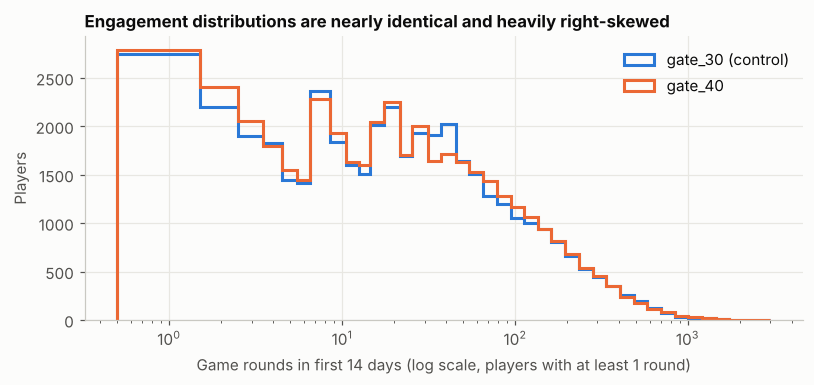

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
bins = np.unique(np.round(np.logspace(0, np.log10(3000), 45))) - 0.5   # integer-aligned log bins
for s, col, lab in [(ga, BLUE, "gate_30 (control)"), (gb, ORANGE, "gate_40")]:
    ax.hist(s[s > 0], bins=bins, histtype="step", lw=2, color=col, label=lab)
ax.set_xscale("log")
ax.set_xlabel("Game rounds in first 14 days (log scale, players with at least 1 round)")
ax.set_ylabel("Players")
ax.set_title("Engagement distributions are nearly identical and heavily right-skewed", loc="left", fontsize=11, weight="bold")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("../figures/gamerounds_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

**Interpretation**

- Game rounds are extremely right-skewed: the median player plays 16 to 17 rounds while the mean is about 51, because a small group of heavy players pulls the average up. A t-test leans on the mean and is sensitive to that tail, so I use a bootstrap confidence interval for the mean difference and a rank-based Mann-Whitney test as a cross-check.
- After removing the one extreme outlier, mean rounds are 51.34 vs 51.30. The bootstrap interval for the difference is roughly −1.3 to +1.3 rounds and is centred on zero. With the outlier left in, the control mean would be 52.46 and would suggest a gap of more than one round that is produced by a single row.
- The Mann-Whitney p-value is 0.051, right at the threshold. It tests whether one distribution tends to produce larger values than the other, not whether the means differ, and here it reflects a small shift around the median (17 vs 16 rounds). I read it as weak evidence that typical players play slightly less under `gate_40`, consistent in direction with the retention result, and not as a finding on its own.
- The histogram shows one visible divergence: control players pile up at roughly 30 to 50 rounds, which is about where the level-30 gate stops them. Rounds are not levels, so I treat this as a plausible trace of the gate rather than proof.
- **Guardrail verdict:** moving the gate does not increase total play volume. There is no engagement gain that could offset the retention loss.

## 5. How sensitive was this test?

In [11]:
for metric in ["retention_1", "retention_7"]:
    base = a[metric].mean()
    mde = mde_two_proportions(base, len(a), len(b))
    obs = abs(res[metric]["abs_diff"])
    n_req = required_n_per_group(base, obs)
    print(f"{metric}: baseline {base:.2%} | MDE at 80% power = {mde*100:.2f} pp | "
          f"observed |diff| = {obs*100:.2f} pp | n per group needed for observed diff = {n_req:,}")

retention_1: baseline 44.82% | MDE at 80% power = 0.93 pp | observed |diff| = 0.59 pp | n per group needed for observed diff = 111,463
retention_7: baseline 19.02% | MDE at 80% power = 0.73 pp | observed |diff| = 0.82 pp | n per group needed for observed diff = 36,533


**Interpretation.** With about 45,000 players per arm, the test could reliably detect (80% power, α = 0.05) a difference of 0.73 pp in 7-day retention and 0.93 pp in 1-day retention.

- The observed 7-day difference (0.82 pp) is above that threshold, so the experiment was adequately sized for the primary metric.
- The observed 1-day difference (0.59 pp) is below it. Detecting an effect that small would need roughly 111,000 players per arm, about 2.5 times the sample we have. The non-significant 1-day result therefore means "not enough data to tell", not "no effect".

I report minimum detectable effect rather than "observed power", because power computed from the observed effect is just a transformation of the p-value and adds no information.

## 6. Conclusion and recommendation

**Recommendation: keep the gate at level 30. Do not ship `gate_40`.**

| Evidence | Result |
|---|---|
| 7-day retention (primary) | −0.82 pp (19.02% → 18.20%), 95% CI [−1.33, −0.31], p = 0.0016 |
| Probability that `gate_40` is better on 7-day retention | about 0.1% |
| 1-day retention (secondary) | −0.59 pp, 95% CI [−1.24, +0.06], p = 0.074: same direction, not conclusive |
| Game rounds (guardrail) | No meaningful difference in mean (bootstrap CI about ±1.3 rounds) |

**What this means in business terms.** A 0.82 pp drop means roughly 8 fewer players out of every 1,000 installs are still playing after a week. For a game acquiring players at scale, that compounds into a meaningful loss of active users, with no offsetting gain in engagement.

**Why would an earlier gate retain better?** The data cannot prove a mechanism, but a plausible explanation is hedonic adaptation: a forced pause before players are saturated leaves them wanting more, so they come back. A later gate lets players binge further and reach the pause closer to the point where they were going to lose interest anyway. This is a hypothesis, not a finding of this analysis.

**Limitations**

1. **Sample ratio.** The SRM check returned p = 0.0086. It did not cross the usual p < 0.001 stop threshold, but the assignment and logging pipeline should be verified before treating the result as final.
2. **No revenue data.** The gate is also a monetisation point, since players can pay to skip it. Retention is a proxy; a later gate could in principle change purchase behaviour in ways this dataset cannot show.
3. **Short horizon.** Outcomes are measured over 14 days at most. Effects on 30-day retention or lifetime value are unknown.
4. **No segments.** There is no information on country, device or acquisition channel, so I cannot check whether the effect differs between player groups.
5. **Single outlier removed** for the game-rounds analysis only; the retention conclusions do not depend on it.

**Next steps I would propose**

- Confirm the randomisation pipeline (SRM follow-up).
- Add revenue per user and 30-day retention as metrics in any follow-up experiment.
- Since the earlier gate did better, test an even earlier gate (for example level 20 or 25) to find where the effect peaks.